In [32]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax.numpy as np

import dLux as dl
import dLux.utils as dlu
import dLuxToliman as dlT
import math
from tqdm import tqdm
from matplotlib.colors import PowerNorm, CenteredNorm
import jax
from jax import vmap
import zodiax as zdx
jax.config.update("jax_enable_x64", True)

cividis = mpl.colormaps["cividis"]
viridis = mpl.colormaps["viridis"]
coolwarm = mpl.colormaps["coolwarm"]

cividis.set_bad("k", 1.0)
viridis.set_bad("k", 1.0)

mpl.colors.Normalize(vmin=-1, vmax=1)

In [33]:
# # Single Mask
# mask_path = "diffractive_pupil.npy"
# phase_mask = np.load(mask_path) * np.pi  # Load the mask and convert to phase
# phase_mask = dlu.downsample(phase_mask, 8)
# phase_mask = dl.Optic(phase=phase_mask)

# opd_mask = np.load(mask_path) * 585*0.5e-9
# opd_mask = dlu.downsample(opd_mask, 8)
# opd_mask = dl.Optic(opd=opd_mask)

# wavelengths = np.linspace(530e-9, 640e-9, 10)  # Define the wavelengths for the simulation

# print(phase_mask.phase.shape)

In [34]:
# Two Masks
phase_mask_path = "phase_optimised_mask_no_wavelengths.npy"
phase_mask = np.load(phase_mask_path) * np.pi # Load the mask and convert to phase
phase_mask = dlu.downsample(phase_mask, 1)
phase_mask = dl.Optic(phase=phase_mask)

opd_mask_path = "diffractive_pupil.npy"
opd_mask = np.load(opd_mask_path) * 585*0.5e-9
opd_mask = dlu.downsample(opd_mask, 8)
opd_mask = dl.Optic(opd=opd_mask)

wavelengths = np.linspace(530e-9, 640e-9, 10)  # Define the wavelengths for the simulation

print(phase_mask.phase.shape)
#print(opd_mask.opd.shape)

(256, 256)


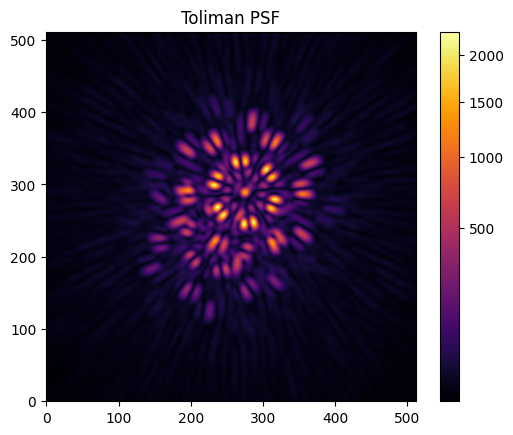

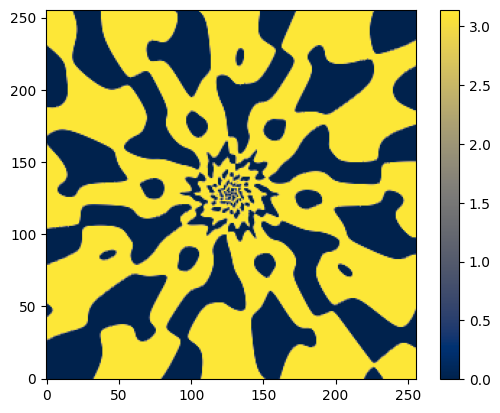

In [35]:
optics = dlT.TolimanOpticalSystem(wf_npixels=phase_mask.phase.shape[0], psf_npixels=128, psf_pixel_scale=0.4219, mask=phase_mask, noll_indices=np.arange(4,11))  # creating Toliman optical system
source = dlT.AlphaCen(
    n_wavels=10, separation=8, position_angle=30, log_flux=np.log10(10**7.581 / 4)
)  # creating Alpha Centauri source
model = dlT.Toliman(source=source, optics=optics)  # creating Toliman telescope

psf_phase = model.model()  # running optical simulation

# plotting
plt.imshow(psf_phase, cmap="inferno", norm=PowerNorm(0.5), origin="lower")
plt.title(r"Toliman PSF")
plt.colorbar()
plt.show()

plt.imshow(model.optics.phase, cmap="cividis", origin="lower")
plt.colorbar()

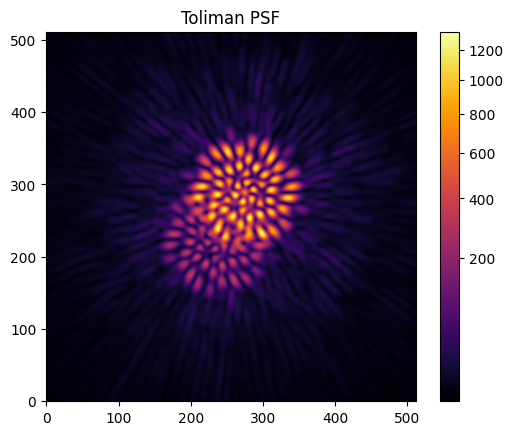

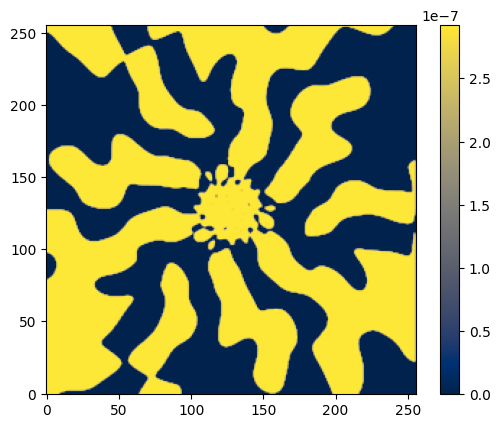

In [36]:
optics = dlT.TolimanOpticalSystem(wf_npixels=256, psf_npixels=128, psf_pixel_scale=0.4219, mask=opd_mask, noll_indices=np.arange(4,11))  # creating Toliman optical system
source = dlT.AlphaCen(
    n_wavels=10, separation=8, position_angle=30, log_flux=np.log10(10**7.581 / 4)
)  # creating Alpha Centauri source
model_opd = dlT.Toliman(source=source, optics=optics)  # creating Toliman telescope

psf_opd = model_opd.model()  # running optical simulation

# plotting
plt.imshow(psf_opd, cmap="inferno", norm=PowerNorm(0.5), origin="lower")
plt.title(r"Toliman PSF")
plt.colorbar()
plt.show()

plt.imshow(model_opd.optics.opd, cmap="cividis", origin="lower")
plt.colorbar()

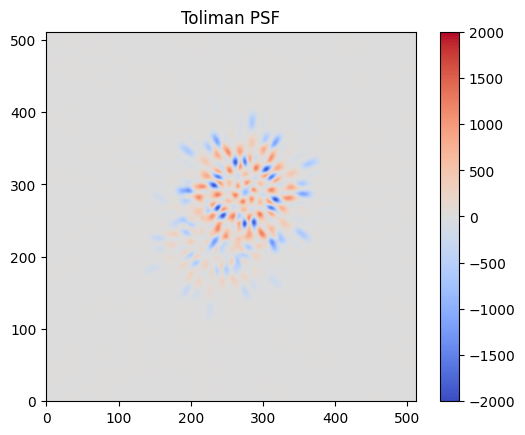

In [37]:
plt.imshow(psf_opd-psf_phase, cmap="coolwarm", origin="lower", norm=CenteredNorm(vcenter=0.0))
plt.title(r"Toliman PSF")
plt.colorbar()
plt.show()

In [38]:
from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


In [39]:
import jax
def loss_fn(params, model, data):
    params = dict(params)
    # Mean wavelength (nm): shift the whole sampled band rigidly so the
    # bandwidth and wavelength spacing stay fixed.
    #mean_wl = params.pop("mean_wavelength")
    #wl = model.source.wavelengths  # nm, from the fiducial model
    model = model.set(params)
    #model = model.set("source.wavelengths", wl - wl.mean() + mean_wl)
    img = model.model()
    loss = -poisson_loglike_gamma(data, img).sum()
    return loss

params = {
    "separation": 8.0,
    "position_angle": 30.0,
    "x_position": 0.0,
    "y_position": 0.0,
    "log_flux": np.log10(10**7.581 / 4), #flux correction
    "contrast": 3.37,
    #"mean_wavelength": float(model.source.wavelengths.mean()),  # nm (585 for 530-640 band)
    "psf_pixel_scale": 0.4219,
    "coefficients": np.zeros(7),
}

f = lambda params: loss_fn(params, model, psf_phase)

from zodiax.diffops import hessian
H, unflatten = hessian(f, params)

H = 0.5 * (H + H.T) # symmetretise

f_opd = lambda params: loss_fn(params, model_opd, psf_opd)

H_opd, unflatten = hessian(f_opd, params)

H_opd = 0.5 * (H_opd + H_opd.T) # symmetretise

# --- Reorder the Hessians -------------------------------------------------
# JAX flattens dicts in *sorted key order*, not insertion order, so the raw
# Hessian rows/cols are ordered: coefficients(7), contrast, log_flux,
# mean_wavelength, position_angle, separation, x_position, y_position.
# Permute them into the order used for plotting/labelling below.
param_order = [
    "separation", 
    "position_angle", 
    "x_position", 
    "y_position",
    "log_flux", 
    "contrast", 
    #"mean_wavelength", 
    "psf_pixel_scale", 
    "coefficients",
]

def flat_index_blocks(tree):
    """Map each top-level key -> its indices in the flattened vector."""
    blocks, start = {}, 0
    for path, leaf in jax.tree_util.tree_flatten_with_path(tree)[0]:
        n = int(np.size(leaf))
        blocks[path[0].key] = np.arange(start, start + n)
        start += n
    return blocks

blocks = flat_index_blocks(params)
perm = np.concatenate([blocks[k] for k in param_order])

H = H[np.ix_(perm, perm)]
H_opd = H_opd[np.ix_(perm, perm)]
# NOTE: `unflatten` from zodiax expects the original (sorted) ordering,
# so don't use it on the permuted matrices.


In [40]:
for path, value in jax.tree_util.tree_flatten_with_path(params)[0]:
    print(jax.tree_util.keystr(path), np.shape(value))
print("Hessian now ordered as:", param_order)

cov = np.linalg.inv(H)
cov_opd = np.linalg.inv(H_opd)

['coefficients'] (7,)
['contrast'] ()
['log_flux'] ()
['position_angle'] ()
['psf_pixel_scale'] ()
['separation'] ()
['x_position'] ()
['y_position'] ()
Hessian now ordered as: ['separation', 'position_angle', 'x_position', 'y_position', 'log_flux', 'contrast', 'psf_pixel_scale', 'coefficients']


0.00031178402760870114
0.00032569219855207966


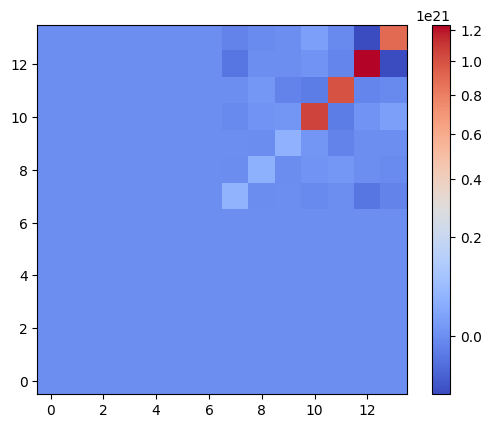

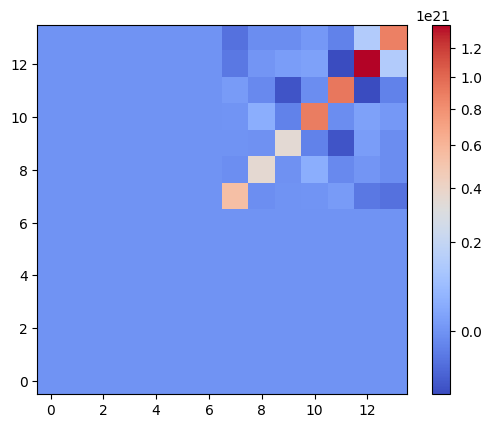

In [41]:
# index 0 is now separation
print(1/np.sqrt(H[0,0]))
print(1/np.sqrt(H_opd[0,0]))

plt.imshow(H, cmap="coolwarm", origin="lower", norm=PowerNorm(0.5))
plt.colorbar()
plt.show()
plt.imshow(H_opd, cmap="coolwarm", origin="lower", norm=PowerNorm(0.5))
plt.colorbar()
plt.show()

In [42]:
# separation variance
print(cov[0][0])
print(cov_opd[0][0])

2.8985036170575913e-07
3.6490861854113205e-07


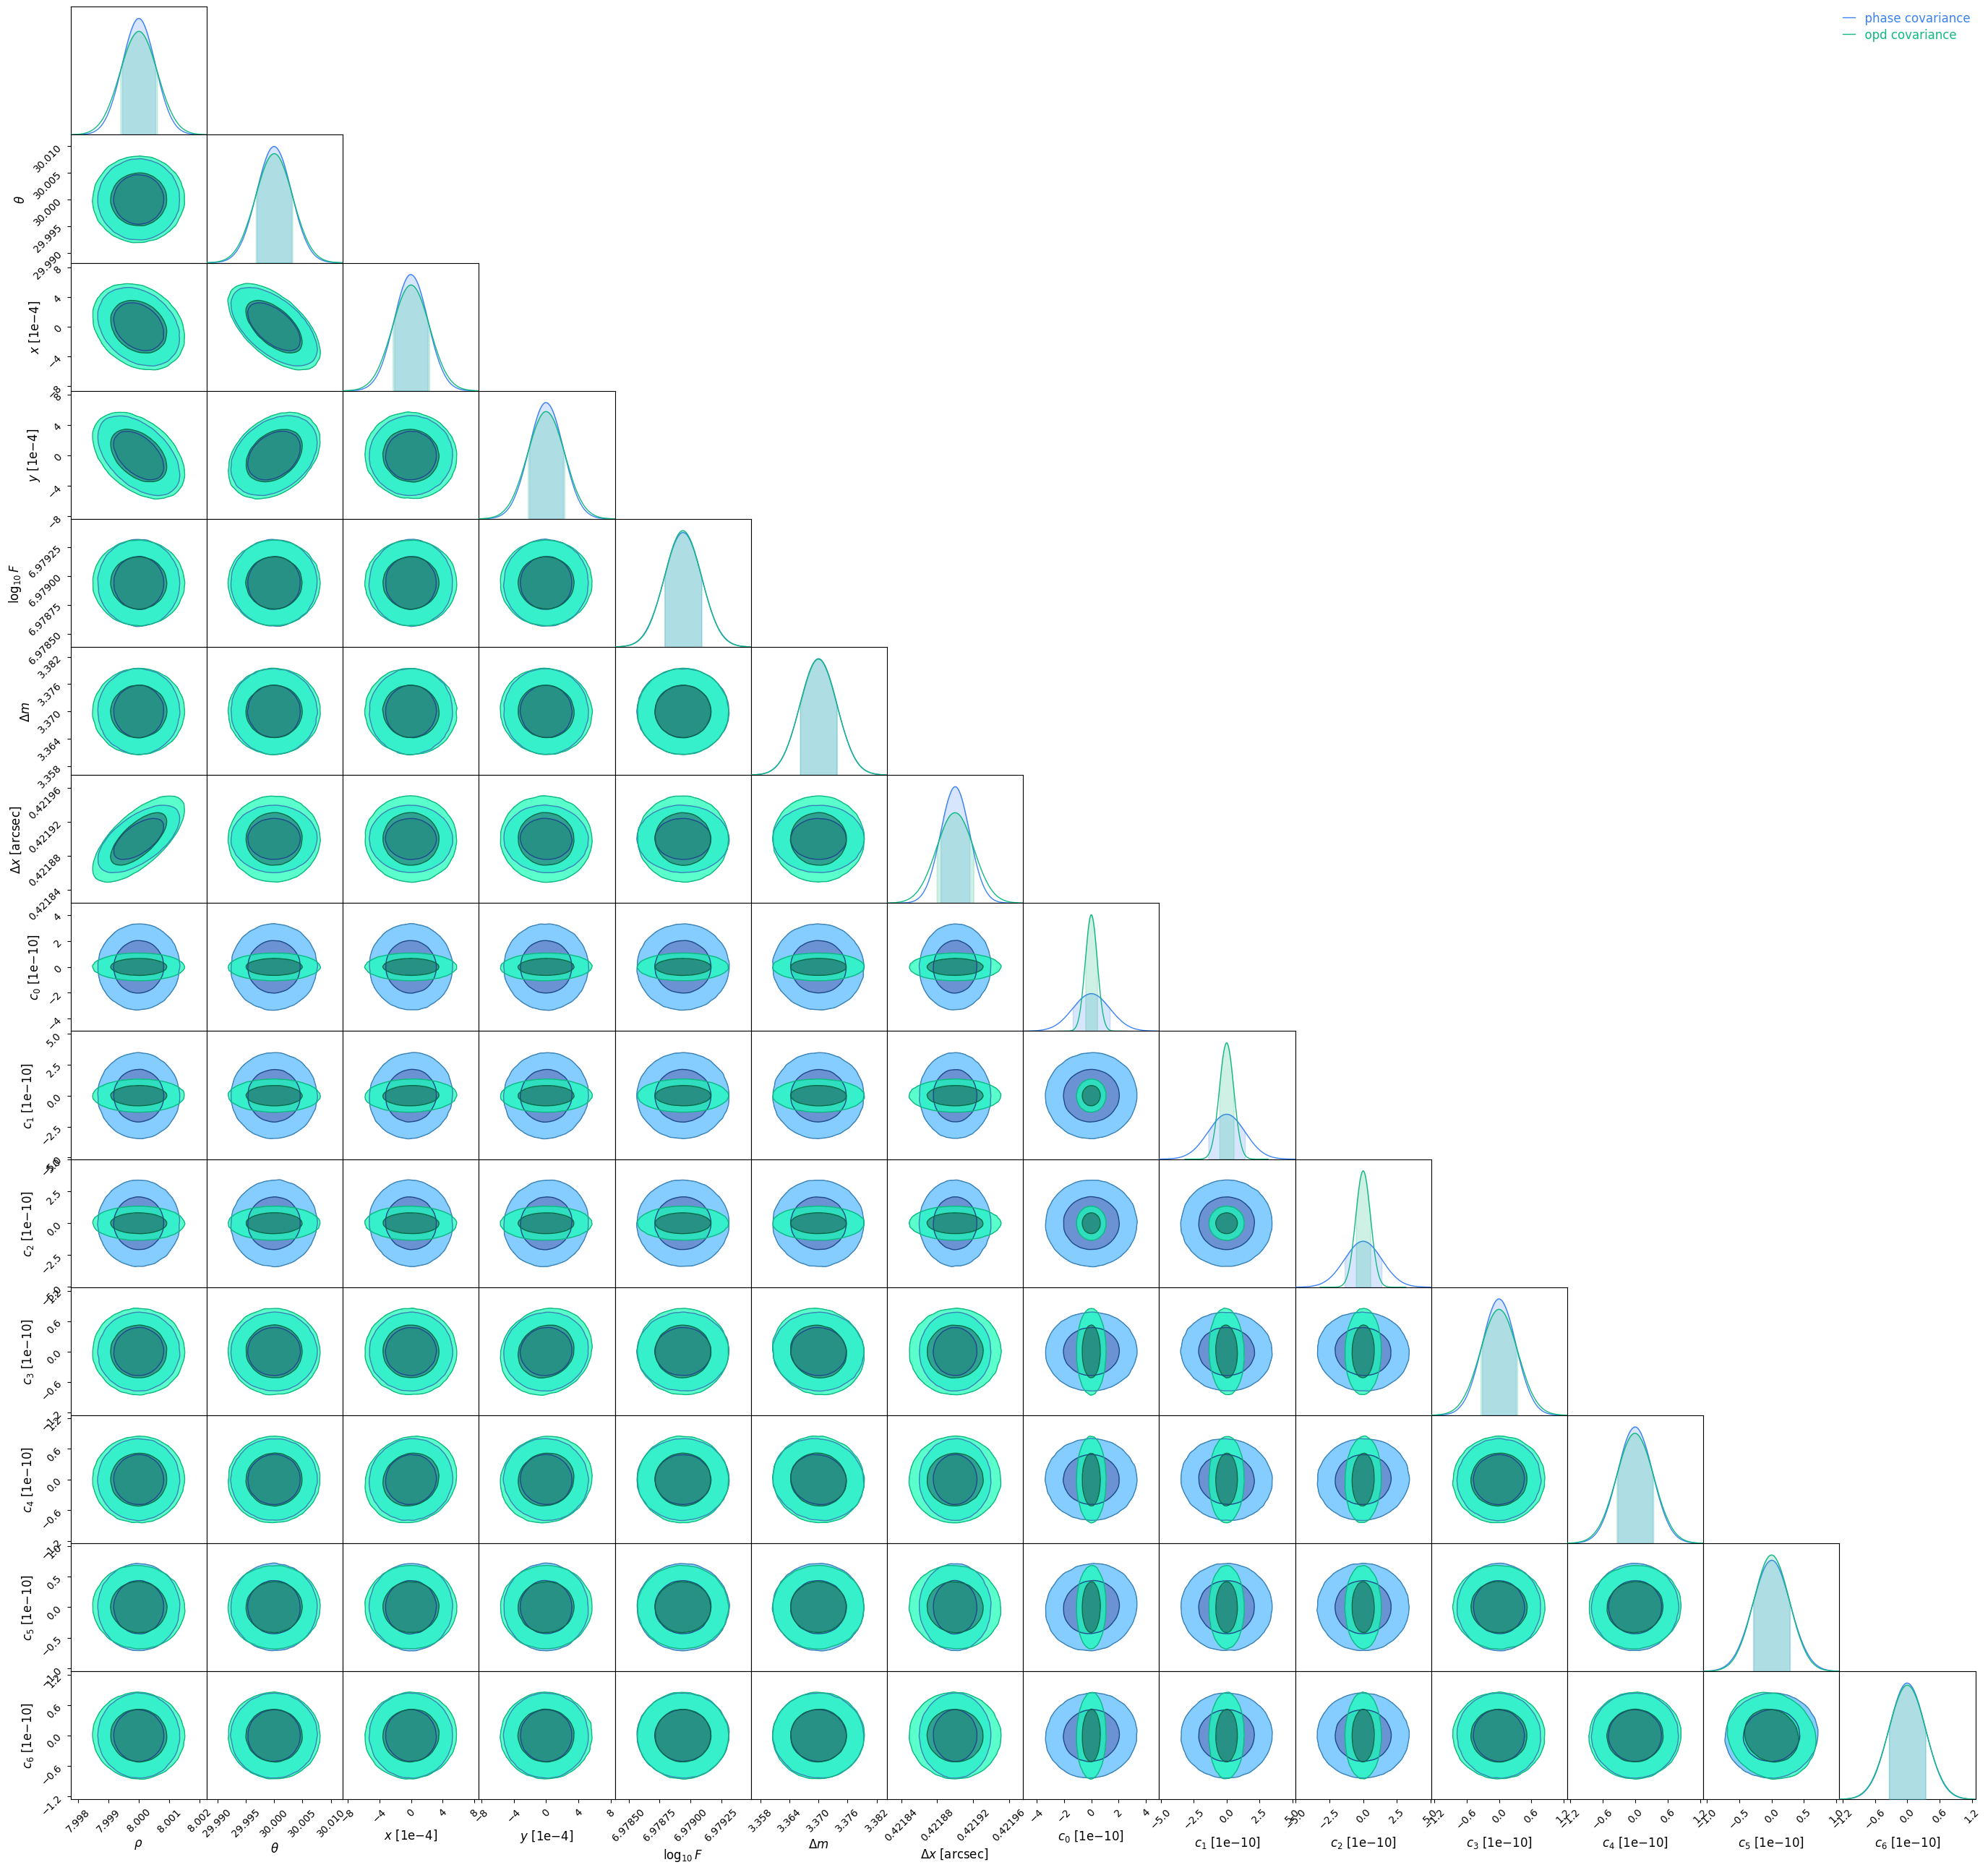

In [43]:
from chainconsumer import Chain, ChainConsumer

columns = [
    r"$\rho$",
    r"$\theta$",
    r"$x$",
    r"$y$",
    r"$\log_{10} F$",
    r"$\Delta m$",
    #r"$\bar{\lambda}$ [nm]",
    r"$\Delta x$ [arcsec]",
] + [rf"$c_{i}$" for i in range(7)]

mean = np.concatenate([
    np.array([
        params["separation"],
        params["position_angle"],
        params["x_position"],
        params["y_position"],
        params["log_flux"],
        params["contrast"],
        #params["mean_wavelength"],
        params["psf_pixel_scale"],
    ]),
    np.asarray(params["coefficients"])
])

c = ChainConsumer()
chain = Chain.from_covariance(
    mean=mean,
    covariance=np.asarray(cov),
    columns=columns,
    name="phase covariance",
)

c.add_chain(chain)

chain = Chain.from_covariance(
    mean=mean,
    covariance=np.asarray(cov_opd),
    columns=columns,
    name="opd covariance",
)
c.add_chain(chain)

fig = c.plotter.plot()

In [44]:
print(cov[0,0]**0.5/cov_opd[0,0]**0.5)

0.8912403959965852
